# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

In [1]:
#code from previous Lab
from pathlib import Path  # import a tool for working with file paths
import pandas as pd  # import pandas for working with tables

def normalize_store_id(values):  # define a function to standardize store ids
    return (values.astype("string").str.strip().str.upper()  # convert to text, trim spaces, and capitalize
            .str.replace(r"^FL[-_ ]?(\d{3})$", r"FL-\1", regex=True))  # standardize matching ids to FL-###

def parse_timestamps(values):  # define a function to parse different date formats
    parsed = pd.Series(pd.NaT, index=values.index, dtype="datetime64[ns]")  # create an empty datetime series
    for fmt in ["%Y-%m-%dT%H:%M:%S", "%Y-%m-%d %H:%M:%S",  # include year-first formats with seconds
                "%m/%d/%Y %H:%M", "%m-%d-%Y %H:%M:%S", "%d-%b-%Y %H:%M"]:  # include the other observed formats
        remaining = parsed.isna()  # identify timestamps that have not been parsed
        parsed.loc[remaining] = pd.to_datetime(  # try parsing the remaining timestamps
            values.loc[remaining], format=fmt, errors="coerce")  # leave unsuccessful conversions as missing
    return parsed  # return the parsed timestamps

def clean_sales(raw):  # define a function to clean the transaction data
    log = []  # create a list to store cleaning decisions

    def record(step, decision, affected, removed=0):  # define a helper to record each decision
        log.append({"step": step, "decision": decision,  # store the step name and explanation
                    "rows_affected": int(affected), "rows_removed": int(removed)})  # store the affected and removed counts
    df = raw.drop_duplicates().copy()  # remove exact duplicates and create a separate dataframe
    removed = len(raw) - len(df)  # calculate the number of duplicate rows removed
    record("duplicates", "Remove exact duplicate rows only", removed, removed)  # log duplicate removal
    price_text = df["unit_price"].astype("string")  # store the original prices as text
    price_clean = (price_text.str.strip().str.replace("$", "", regex=False)  # remove surrounding spaces and dollar signs
                   .str.replace(",", "", regex=False))  # remove commas from prices
    df["unit_price"] = pd.to_numeric(price_clean, errors="coerce")  # convert prices to numbers and invalid values to missing
    record("price format", "Remove dollar signs and whitespace; convert to numeric",  # describe price formatting
           price_text.ne(price_clean).sum())  # count prices whose text changed
    df["invalid_price"] = df["unit_price"].isna()  # flag missing or unparseable prices
    record("invalid price", "Keep and flag missing or unparseable prices",  # describe the invalid-price policy
           df["invalid_price"].sum())  # count flagged prices

    df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")  # convert quantities to numbers
    df["negative_quantity"] = df["quantity"].lt(0)  # flag quantities below zero without removing them
    record("negative quantity", "Keep signed values and flag; meaning needs confirmation",  # describe the negative-quantity policy
           df["negative_quantity"].sum())  # count negative quantities

    df["timestamp_raw"] = df["timestamp"]  # preserve the original timestamp values
    df["timestamp"] = parse_timestamps(df["timestamp"])  # convert timestamps using the supported formats
    df["missing_timestamp"] = df["timestamp"].isna()  # flag missing or unparseable timestamps
    record("timestamp parsing", "Parse five explicit date formats",  # describe timestamp conversion
           df["timestamp"].notna().sum())  # count successfully parsed timestamps
    record("missing timestamp", "Keep and flag; exclude explicitly from date-based analyses",  # record the policy for later date-based analysis
           df["missing_timestamp"].sum())  # count rows that still lack timestamps

    original_ids = df["store_id"].copy()  # preserve store ids for comparison
    df["store_id"] = normalize_store_id(df["store_id"])  # standardize transaction store ids
    record("store_id", "Normalize case, spaces and separators to FL-###",  # describe store id cleaning
           original_ids.ne(df["store_id"]).sum())  # count store ids that changed

    print(f"Before: {len(raw):,}")  # display the original transaction count
    print(f"After: {len(df):,}")  # display the cleaned transaction count
    print(f"Rows removed: {len(raw) - len(df):,}")  # display the number of removed transactions
    return df, pd.DataFrame(log)  # return cleaned transactions and the decision log


def clean_stores(raw):  # define a function to clean the store data
    df = raw.copy()  # create a copy to preserve the input data
    df["store_id"] = normalize_store_id(df["store_id"])  # standardize store ids for matching
    df["state"] = df["state"].str.strip().replace({"Florida": "FL", "Fla.": "FL"})  # standardize state names
    df["region"] = df["region"].str.strip()  # remove surrounding spaces from region names
    for col in ["latitude", "longitude"]:  # loop through both coordinate columns
        df[col] = pd.to_numeric(df[col], errors="coerce")  # convert coordinates to numbers and invalid values to missing
    df = df.drop_duplicates()  # remove identical store records after standardization
    if df["store_id"].duplicated().any():  # check whether different records share a store id
        raise ValueError("Conflicting store records need manual review")  # stop if store records conflict
    print(f"Store rows: {len(raw)} -> {len(df)}")  # display store counts before and after cleaning
    return df  # return the cleaned store data

def run_checkpoint(data_dir="."):  # define the workflow using the current folder by default
    data_dir = Path(data_dir)  # convert the folder location to a path object
    raw_sales = pd.read_csv(data_dir / "walmart_transactions.csv", dtype="string")  # load transactions as text
    raw_stores = pd.read_csv(data_dir / "store_locations.csv", dtype="string")  # load stores as text
    cleaned_sales, decision_log = clean_sales(raw_sales)  # clean transactions and collect their decision log
    cleaned_stores = clean_stores(raw_stores)  # clean the store information
    sales_with_stores = cleaned_sales.merge(  # attach store information to transactions
        cleaned_stores, on="store_id", how="left", validate="many_to_one", indicator=True)  # retain all transactions and require unique store matches
    print("Unmatched store IDs:", int(sales_with_stores["_merge"].eq("left_only").sum()))  # display the number of transactions without a store match
    print("\nDecision log (Section 2):")  # print a heading for the decision log
    print(decision_log.to_string(index=False))  # display the log without row index numbers
    return cleaned_sales, cleaned_stores, decision_log, sales_with_stores  # return the four results

cleaned_sales, cleaned_stores, decision_log, sales_with_stores = run_checkpoint()  # run the workflow and save its results

Before: 25,562
After: 25,532
Rows removed: 30
Store rows: 14 -> 12
Unmatched store IDs: 0

Decision log (Section 2):
             step                                                   decision  rows_affected  rows_removed
       duplicates                           Remove exact duplicate rows only             30            30
     price format     Remove dollar signs and whitespace; convert to numeric           4329             0
    invalid price                Keep and flag missing or unparseable prices              0             0
negative quantity    Keep signed values and flag; meaning needs confirmation            130             0
timestamp parsing                           Parse five explicit date formats          24648             0
missing timestamp Keep and flag; exclude explicitly from date-based analyses            884             0
         store_id            Normalize case, spaces and separators to FL-###           4345             0


In [2]:
# Package sizes differ, so original SKUs are preserved.
sku_mapping = {
    "PT-12": "Pop-Tarts Strawberry",
    "SKU#459812": "Pop-Tarts Strawberry",
    "POPTART-STRAW": "Pop-Tarts Strawberry",
    "PT_STRAWBERRY": "Pop-Tarts Strawberry",
}

# Unreviewed products keep their original SKU as their identifier.
cleaned_sales["canonical_product"] = (cleaned_sales["sku"].map(sku_mapping).fillna(cleaned_sales["sku"]))
before = cleaned_sales["sku"].nunique()
after = cleaned_sales["canonical_product"].nunique()

group_sizes = (cleaned_sales.groupby("canonical_product")["sku"].nunique().sort_values(ascending=False))

print("Original distinct SKUs:", before)
print("Current canonical groups (partial):", after)
print("Largest group:", group_sizes.index[0])
print("SKUs in largest group:", group_sizes.iloc[0])

mapping_table = pd.DataFrame(sku_mapping.items(),columns=["original_sku", "canonical_product"])
display(mapping_table)

print(
    "Status: partial. Four strawberry Pop-Tarts SKUs are grouped "
    "at the product-family level. Package sizes still need review; "
    "other SKUs remain separate."
)

Original distinct SKUs: 45
Current canonical groups (partial): 42
Largest group: Pop-Tarts Strawberry
SKUs in largest group: 4


,original_sku,canonical_product
0,PT-12,Pop-Tarts Strawberry
1,SKU#459812,Pop-Tarts Strawberry
2,POPTART-STRAW,Pop-Tarts Strawberry
3,PT_STRAWBERRY,Pop-Tarts Strawberry


Status: partial. Four strawberry Pop-Tarts SKUs are grouped at the product-family level. Package sizes still need review; other SKUs remain separate.


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [3]:
# TODO: the numbers
import pandas as pd
q1_sales = cleaned_sales.dropna(subset=["timestamp"]).copy()
q1_sales["date"] = q1_sales["timestamp"].dt.normalize()
daily_units = q1_sales.groupby(["date", "canonical_product"]
)["quantity"].sum().unstack(fill_value=0)
daily_units = daily_units.reindex(
    pd.date_range("2024-09-01", "2024-09-30"),
    fill_value=0)
baseline_start = "2024-09-01"
baseline_end = "2024-09-14"
surge_start = "2024-09-21"
surge_end = "2024-09-25"
baseline_avg = daily_units.loc[baseline_start:baseline_end].mean()
surge_avg = daily_units.loc[surge_start:surge_end].mean()
q1_results = pd.DataFrame({"baseline_daily_avg": baseline_avg,
    "surge_daily_avg": surge_avg})
q1_results["surge_multiple"] = (surge_avg /baseline_avg.where(baseline_avg > 0))
q1_results = q1_results.sort_values("surge_multiple", ascending=False)
print("Baseline:", baseline_start,"to", baseline_end)
print("Surge:", surge_start, "to", surge_end)
display(q1_results)

Baseline: 2024-09-01 to 2024-09-14
Surge: 2024-09-21 to 2024-09-25


,baseline_daily_avg,surge_daily_avg,surge_multiple
canonical_product,,,
Pop-Tarts Strawberry,73.642857,463.2,6.289816
HDTARP-01,18.428571,78.6,4.265116
FLASH-01,26.928571,105.4,3.914058
WATER24PK,35.071429,130.0,3.706721
BATT-100,27.785714,102.8,3.699743
WTR-24,35.214286,123.0,3.492901
BATT_AA_4PK,25.571429,84.6,3.30838
WTR_24PK,38.357143,125.0,3.258845
PORTCHARGER,19.285714,62.4,3.235556


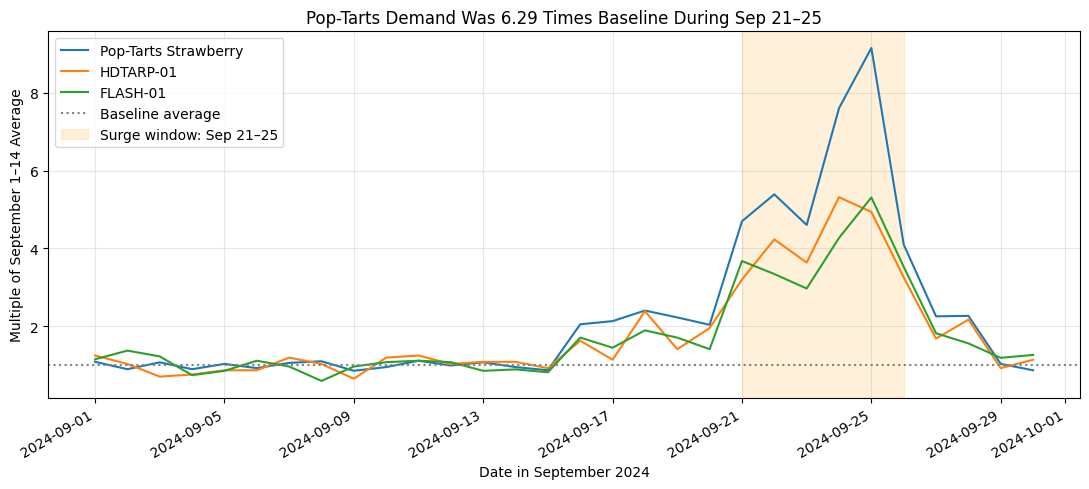

In [13]:
# TODO: the chart
import matplotlib.pyplot as plt
top_products =q1_results.dropna(subset=["surge_multiple"]).head(3).index
indexed_units = daily_units[top_products].div(baseline_avg[top_products])
fig, ax = plt.subplots(figsize=(11, 5))
for product in top_products:
    ax.plot(indexed_units.index,
        indexed_units[product],
        label=product)
ax.axhline(1, color="gray", linestyle=":", label="Baseline average")
ax.axvspan(pd.Timestamp(surge_start),
    pd.Timestamp(surge_end) +pd.Timedelta(days=1),
    color="orange",
    alpha=0.15,
    label="Surge window: Sep 21–25")
ax.set_title("Pop-Tarts Demand Was 6.29 Times Baseline During Sep 21–25")
ax.set_xlabel("Date in September 2024")
ax.set_ylabel("Multiple of September 1–14 Average")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Q1 answer, in one sentence a manager could read: Strawberry Pop-Tarts had an average daily quantity of 463.2 during September 21–25, about 6.29 times the average of 73.64 during September 1–14.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Original SKUs: 45
Current product groups: 42
Largest family: Pop-Tarts Strawberry
SKUs in this family: 4
Total quantity is unchanged: 49343
Before consolidation:


,quantity
sku,
POPTART-STRAW,1294
PT-12,1377
PT_STRAWBERRY,1254
SKU#459812,1253


After consolidation:


,quantity
canonical_product,
Pop-Tarts Strawberry,5178


Combined quantity / largest single SKU: 3.7603485838779958


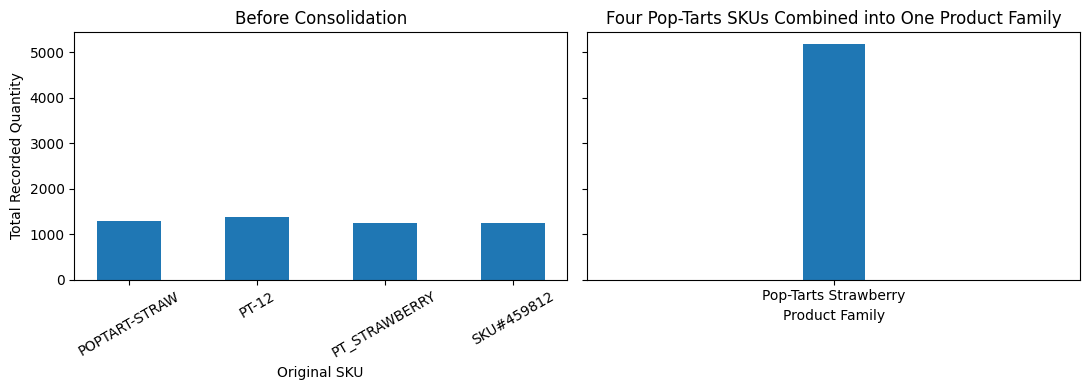

In [14]:
# TODO
print("Original SKUs:", cleaned_sales["sku"].nunique())
print("Current product groups:", cleaned_sales["canonical_product"].nunique())
family_sizes = cleaned_sales.groupby("canonical_product")["sku"].nunique()
largest_family = family_sizes.idxmax()
print("Largest family:", largest_family)
print("SKUs in this family:",family_sizes[largest_family])
before = cleaned_sales.groupby("sku")["quantity"].sum()
after = cleaned_sales.groupby("canonical_product")["quantity"].sum()
assert before.sum() == after.sum()
assert after.sum() == cleaned_sales["quantity"].sum()
print("Total quantity is unchanged:", after.sum())
family_sales = cleaned_sales[cleaned_sales["canonical_product"] == largest_family]
family_before = family_sales.groupby("sku")["quantity"].sum()
family_after = after.loc[[largest_family]]
assert family_before.sum() == family_after.sum()
print("Before consolidation:")
display(family_before)
print("After consolidation:")
display(family_after)
multiple = family_after.sum() /family_before.max()
print("Combined quantity / largest single SKU:", multiple)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].bar(family_before.index, family_before.values, width=0.5)
axes[0].set_title("Before Consolidation")
axes[0].set_xlabel("Original SKU")
axes[0].set_ylabel("Total Recorded Quantity")
axes[0].tick_params(axis="x", labelrotation=30)
axes[1].bar(family_after.index, family_after.values, width=0.5)
axes[1].set_xlim(-2, 2)
axes[1].set_title("Four Pop-Tarts SKUs Combined into One Product Family")
axes[1].set_xlabel("Product Family")
plt.tight_layout()
plt.show()

**Q2 answer:** We started with 45 SKUs and currently have 42 product groups. The largest combined family is strawberry Pop-Tarts. There are four SKUs, 5178 in recorded quantity in total, about 3.76 times the largest single SKU, 1377. Our assertions confirmed that the overall quantity stayed at 49343 after consolidation. Other product families and package sizes still needs review.

In [11]:
#code from previous Lab
import time  # import a tool for waiting between attempts
import requests  # import a tool for making api requests
import pandas as pd  # import pandas for working with tables

def fetch_weather():  # define a function to request daily weather
    url = "https://archive-api.open-meteo.com/v1/archive"  # set the historical weather endpoint
    params = {  # define the location, dates, and weather variables
        "latitude": 28.5383,  # use the Orlando store latitude
        "longitude": -81.3792,  # use the Orlando store longitude
        "start_date": "2024-09-01",  # set the first date
        "end_date": "2024-09-30",  # set the last date
        "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max",  # request daily temperature, rain, and wind
        "timezone": "America/New_York",  # request days based on Orlando local time
        "temperature_unit": "celsius",  # request temperature in degrees Celsius
        "wind_speed_unit": "kmh",  # request wind speed in kilometers per hour
        "precipitation_unit": "mm",  # request precipitation in millimeters
    }  # finish the request parameters

    for attempt in range(3):  # allow up to three attempts
        try:  # try sending the request
            response = requests.get(url, params=params, timeout=30)  # wait at most 30 seconds for a response
            response.raise_for_status()  # raise an error for an unsuccessful http response
            data = response.json()  # parse the response into a dictionary
            break  # stop retrying after a successful request
        except requests.exceptions.RequestException as error:  # catch request failures
            print(f"Attempt {attempt + 1} failed: {error}")  # show the actual error
            if attempt == 2:  # check whether all attempts have failed
                raise  # stop and preserve the final error
            time.sleep(2 ** attempt)  # wait one second and then two seconds before retrying

    weather = pd.DataFrame(data["daily"])  # convert daily weather into a dataframe
    weather = weather.rename(columns={"time": "date"})  # rename the daily time column
    weather["date"] = pd.to_datetime(weather["date"])  # parse the local calendar dates
    weather["store_id"] = "FL-239"  # identify the store represented by these coordinates
    weather["timezone"] = params["timezone"]  # record the timezone used for daily aggregation
    weather["source"] = "Open-Meteo Historical Weather API"  # record the data source
    print("Request URL:", response.url)  # show the actual api request
    print("Units:", data["daily_units"])  # show the units returned by the api
    return weather  # return the parsed weather data

weather_df = fetch_weather()  # request and parse the weather data
print("Weather rows:", len(weather_df))  # display the number of returned days
display(weather_df)  # display the weather table

Request URL: https://archive-api.open-meteo.com/v1/archive?latitude=28.5383&longitude=-81.3792&start_date=2024-09-01&end_date=2024-09-30&daily=temperature_2m_mean%2Cprecipitation_sum%2Cwind_speed_10m_max&timezone=America%2FNew_York&temperature_unit=celsius&wind_speed_unit=kmh&precipitation_unit=mm
Units: {'time': 'iso8601', 'temperature_2m_mean': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h'}
Weather rows: 30


,date,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,store_id,timezone,source
0,2024-09-01,25.8,6.4,18.7,FL-239,America/New_York,Open-Meteo Historical Weather API
1,2024-09-02,25.9,22.0,12.7,FL-239,America/New_York,Open-Meteo Historical Weather API
2,2024-09-03,26.1,32.7,20.6,FL-239,America/New_York,Open-Meteo Historical Weather API
3,2024-09-04,26.2,21.2,12.6,FL-239,America/New_York,Open-Meteo Historical Weather API
4,2024-09-05,25.8,20.8,15.2,FL-239,America/New_York,Open-Meteo Historical Weather API
5,2024-09-06,26.3,4.1,8.0,FL-239,America/New_York,Open-Meteo Historical Weather API
6,2024-09-07,25.8,4.5,12.1,FL-239,America/New_York,Open-Meteo Historical Weather API
7,2024-09-08,26.1,58.8,10.5,FL-239,America/New_York,Open-Meteo Historical Weather API
8,2024-09-09,25.3,19.5,10.4,FL-239,America/New_York,Open-Meteo Historical Weather API
9,2024-09-10,26.0,14.7,12.0,FL-239,America/New_York,Open-Meteo Historical Weather API


### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Rows excluded for missing timestamps: 75
Rows before join: 30
Rows after join: 30
Unmatched days: 0
Weather data: live API response, no fallback
Source: ['Open-Meteo Historical Weather API']
Weather timezone: ['America/New_York']
Days used for correlations: 30
Wind correlation: 0.4532265378699043
Precipitation correlation: -0.2547522735345766


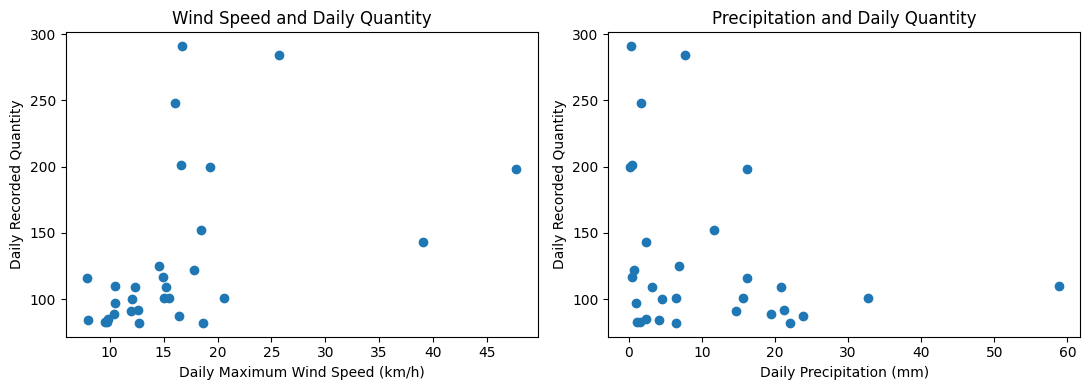

In [12]:
# TODO
store_sales = cleaned_sales[cleaned_sales["store_id"] == "FL-239"].copy()
print("Rows excluded for missing timestamps:", store_sales["timestamp"].isna().sum())
store_sales = store_sales.dropna(subset=["timestamp"])
store_sales["date"] = store_sales["timestamp"].dt.normalize()
daily_sales = store_sales.groupby(["store_id", "date"], as_index=False)["quantity"].sum()
store_weather = weather_df[weather_df["store_id"] == "FL-239"].copy()
rows_before = len(daily_sales)
weather_sales = daily_sales.merge(
    store_weather,
    on=["store_id", "date"],
    how="left",
    validate="one_to_one",
    indicator=True)
print("Rows before join:", rows_before)
print("Rows after join:", len(weather_sales))
print("Unmatched days:", (weather_sales["_merge"] == "left_only").sum())
assert len(weather_sales) == rows_before
assert weather_sales["_merge"].eq("both").all()
assert daily_sales["quantity"].sum() == weather_sales["quantity"].sum()
print("Weather data: live API response, no fallback")
print("Source:", store_weather["source"].unique())
print("Weather timezone:", store_weather["timezone"].unique())
correlation_data = weather_sales.dropna(subset=["quantity", "wind_speed_10m_max", "precipitation_sum"])
wind_correlation = correlation_data["quantity"].corr(correlation_data["wind_speed_10m_max"])
rain_correlation = correlation_data["quantity"].corr(correlation_data["precipitation_sum"])
print("Days used for correlations:", len(correlation_data))
print("Wind correlation:", wind_correlation)
print("Precipitation correlation:", rain_correlation)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(correlation_data["wind_speed_10m_max"],
                correlation_data["quantity"])
axes[0].set_title("Wind Speed and Daily Quantity")
axes[0].set_xlabel("Daily Maximum Wind Speed (km/h)")
axes[0].set_ylabel("Daily Recorded Quantity")
axes[1].scatter(correlation_data["precipitation_sum"],
                correlation_data["quantity"])
axes[1].set_title("Precipitation and Daily Quantity")
axes[1].set_xlabel("Daily Precipitation (mm)")
axes[1].set_ylabel("Daily Recorded Quantity")
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** We used data directly from the Open-Meteo API, with no fallback. There are 30 rows before and after the join. All days are matched. Over these 30 days at the Orlando store, the correlation between daily quantity and wind speed was 0.45, and the correlation with precipitation was −0.25. However, we only looked at one store for one month and excluded 75 transactions with missing timestamps. We also assumed sales dates were in local time, which still needs to be checked. These results cannot result in the conclusion that weather caused the changes in sales.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Jiaxian Wang is working on Q4 and will finish it this weekend.

**Q5 (signal or artifact):** Anya Chang is working on Q5 and will finish it this weekend.

### Self-check

In [16]:
progress = {
    'q1_multiple': 6.29,            # TODO: a number
    'q1_baseline_window': 'September 1–14, 2024',   # TODO: stated explicitly
    'q2_canonical_products': 42,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': 2,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 6.29
PASS - q1_baseline_window = September 1–14, 2024
PASS - q2_canonical_products = 42
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 2
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a) We were surprised that the strawberry Pop-Tarts average is 6.29 times the baseline quantity during September 21–25. We removed exact duplicate rows, checked the daily chart, and used assertions to confirm that the process of combining four SKUs did not change the total quantity.

b) We are least confident of the wind correlation of 0.45 because it only covers 30 days at one store. We excluded 75 transactions with missing timestamps, and the sales timezone still needs to be confirmed.